In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Read in the Excel files
all_weeks_countries_netflix = pd.read_excel('all-weeks-countries-netflix.xlsx')
all_weeks_global_netflix = pd.read_excel('all-weeks-global-netflix.xlsx')
most_popular_netflix = pd.read_excel('most-popular-netflix.xlsx')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [3]:
all_weeks_countries_netflix.sample(30).to_csv('all_weeks_countries_netflix_sample.csv', index=False)
all_weeks_global_netflix.sample(30).to_csv('all_weeks_global_netflix_sample.csv', index=False)
most_popular_netflix.sample(30).to_csv('most_popular_netflix_sample.csv', index=False)

In [4]:

print(all_weeks_global_netflix['category'].unique())


['Films (English)' 'Films (Non-English)' 'TV (English)' 'TV (Non-English)']


In [5]:
category_sums = all_weeks_global_netflix.groupby('category')['weekly_hours_viewed'].sum()
print(category_sums)

category
Films (English)        22069420000
Films (Non-English)     9680460000
TV (English)           46591630000
TV (Non-English)       29740210000
Name: weekly_hours_viewed, dtype: int64


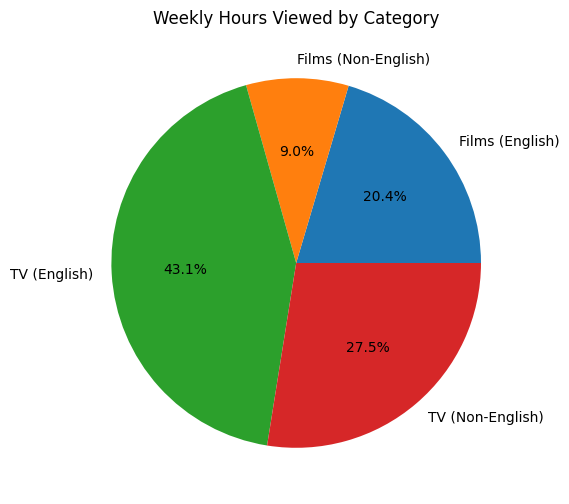

In [6]:
import matplotlib.pyplot as plt

category_sums.plot.pie(autopct='%1.1f%%', figsize=(6, 6), ylabel='', title='Weekly Hours Viewed by Category')
plt.show()

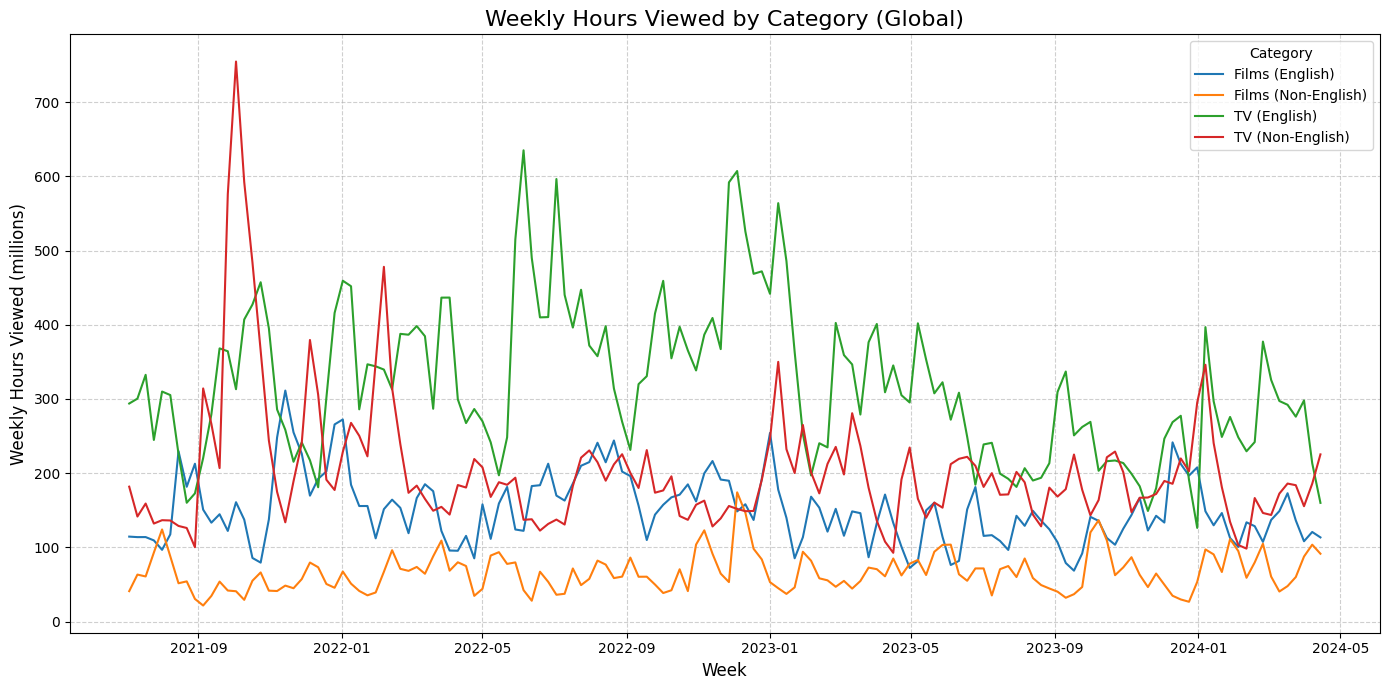

In [7]:
# Convert week to datetime
all_weeks_global_netflix["week"] = pd.to_datetime(all_weeks_global_netflix["week"], errors="coerce")

# Group by week and category, summing hours viewed
weekly_trends = (
    all_weeks_global_netflix.groupby(["week", "category"])["weekly_hours_viewed"]
    .sum()
    .reset_index()
)

# Pivot for plotting
pivot_trends = weekly_trends.pivot(index="week", columns="category", values="weekly_hours_viewed")

# Convert to millions for better readability
pivot_trends_millions = pivot_trends / 1e6

plt.figure(figsize=(14, 7))
for col in pivot_trends_millions.columns:
    plt.plot(pivot_trends_millions.index, pivot_trends_millions[col], label=col)

plt.title("Weekly Hours Viewed by Category (Global)", fontsize=16)
plt.xlabel("Week", fontsize=12)
plt.ylabel("Weekly Hours Viewed (millions)", fontsize=12)
plt.legend(title="Category")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


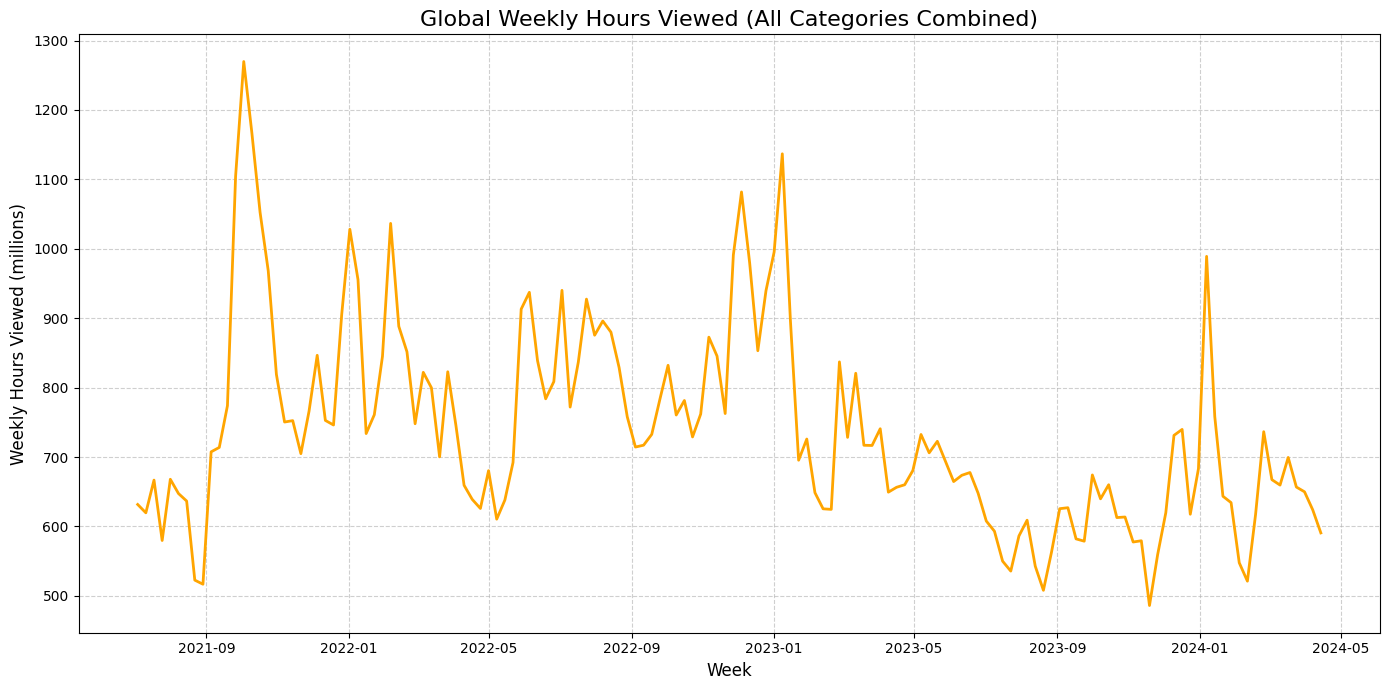

In [12]:
# Convert week to datetime
all_weeks_global_netflix["week"] = pd.to_datetime(all_weeks_global_netflix["week"], errors="coerce")

# Group by week only, summing across all categories
weekly_trends = (
    all_weeks_global_netflix.groupby("week")["weekly_hours_viewed"]
    .sum()
    .reset_index()
)

# Convert to millions for better readability
weekly_trends["weekly_hours_viewed_millions"] = weekly_trends["weekly_hours_viewed"] / 1e6

# Plot overall trend
plt.figure(figsize=(14, 7))
plt.plot(
    weekly_trends["week"],
    weekly_trends["weekly_hours_viewed_millions"],
    color="orange",
    linewidth=2,
)

plt.title("Global Weekly Hours Viewed (All Categories Combined)", fontsize=16)
plt.xlabel("Week", fontsize=12)
plt.ylabel("Weekly Hours Viewed (millions)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


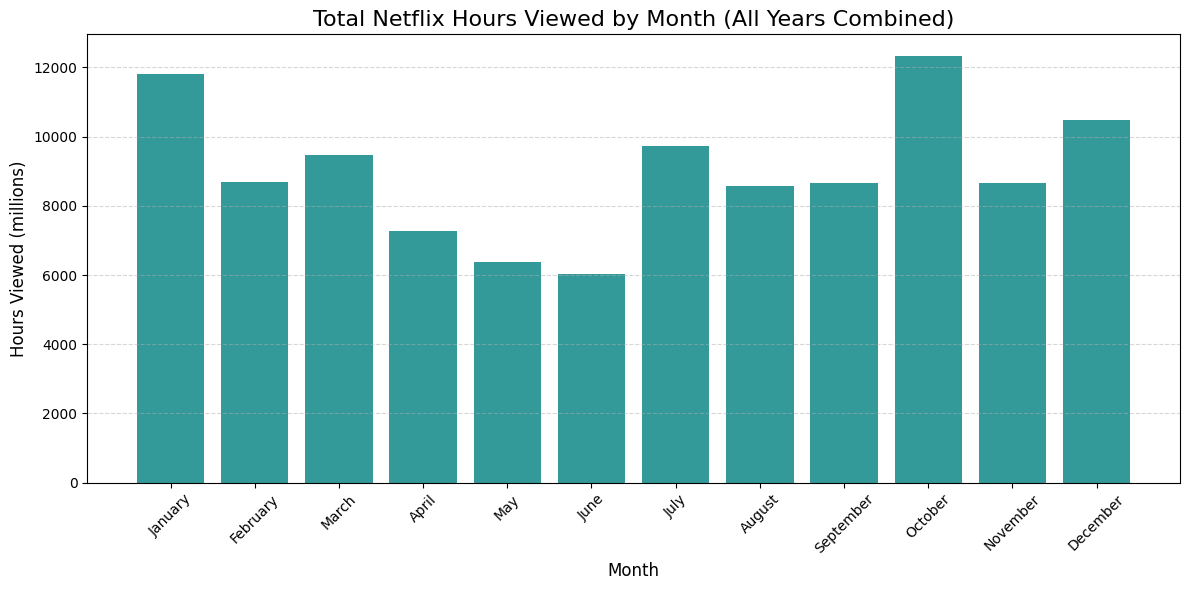

In [14]:
# Ensure week column is datetime
all_weeks_global_netflix["week"] = pd.to_datetime(all_weeks_global_netflix["week"], errors="coerce")

# Extract month number and name
all_weeks_global_netflix["month_num"] = all_weeks_global_netflix["week"].dt.month
all_weeks_global_netflix["month_name"] = all_weeks_global_netflix["week"].dt.month_name()

# Group by month number (to keep correct order), summing across all years
monthly_trends = (
    all_weeks_global_netflix.groupby(["month_num", "month_name"])["weekly_hours_viewed"]
    .sum()
    .reset_index()
    .sort_values("month_num")
)

# Convert to millions
monthly_trends["views_millions"] = monthly_trends["weekly_hours_viewed"] / 1e6

# Plot bar chart
plt.figure(figsize=(12, 6))
plt.bar(monthly_trends["month_name"], monthly_trends["views_millions"], color="teal", alpha=0.8)

plt.title("Total Netflix Hours Viewed by Month (All Years Combined)", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Hours Viewed (millions)", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()


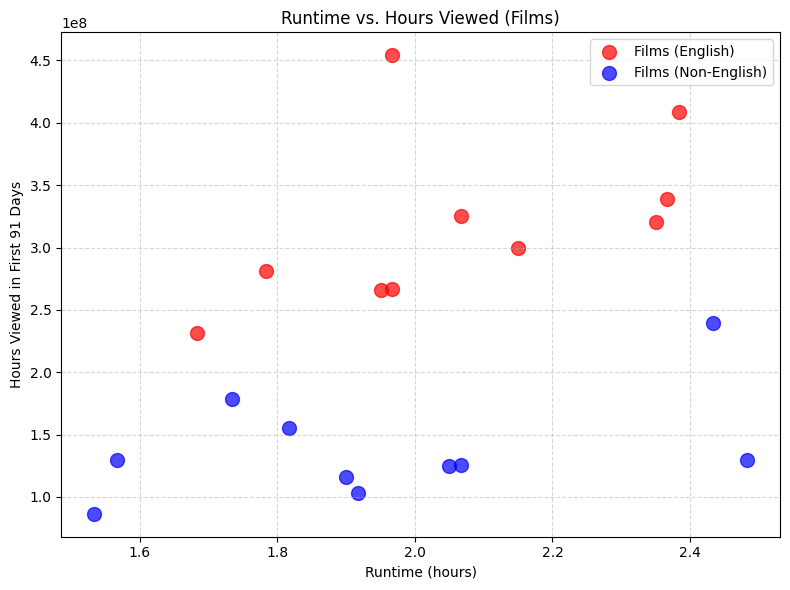

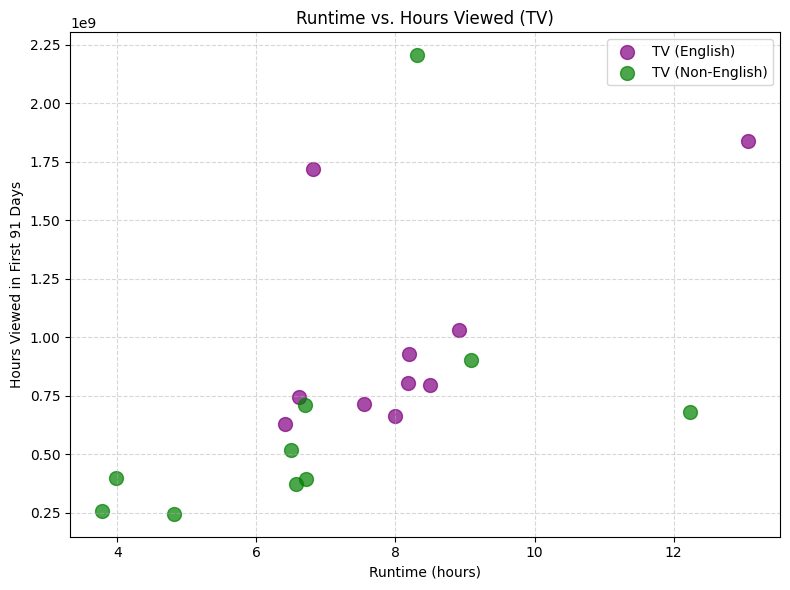

In [8]:

# Scatter plot for Films (English) and Films (Non-English)
films_df = most_popular_netflix[most_popular_netflix['category'].isin(['Films (English)', 'Films (Non-English)'])]

plt.figure(figsize=(8, 6))
for cat, color in zip(['Films (English)', 'Films (Non-English)'], ['red', 'blue']):
    subset = films_df[films_df['category'] == cat]
    plt.scatter(subset['runtime'], subset['hours_viewed_first_91_days'], alpha=0.7, label=cat, color=color, s=100)
plt.xlabel('Runtime (hours)')
plt.ylabel('Hours Viewed in First 91 Days')
plt.title('Runtime vs. Hours Viewed (Films)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Scatter plot for TV (English) and TV (Non-English)
tv_df = most_popular_netflix[most_popular_netflix['category'].isin(['TV (English)', 'TV (Non-English)'])]

plt.figure(figsize=(8, 6))
for cat, color in zip(['TV (English)', 'TV (Non-English)'], ['purple', 'green']):
    subset = tv_df[tv_df['category'] == cat]
    plt.scatter(subset['runtime'], subset['hours_viewed_first_91_days'], alpha=0.7, label=cat, color=color, s=100)
plt.xlabel('Runtime (hours)')
plt.ylabel('Hours Viewed in First 91 Days')
plt.title('Runtime vs. Hours Viewed (TV)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

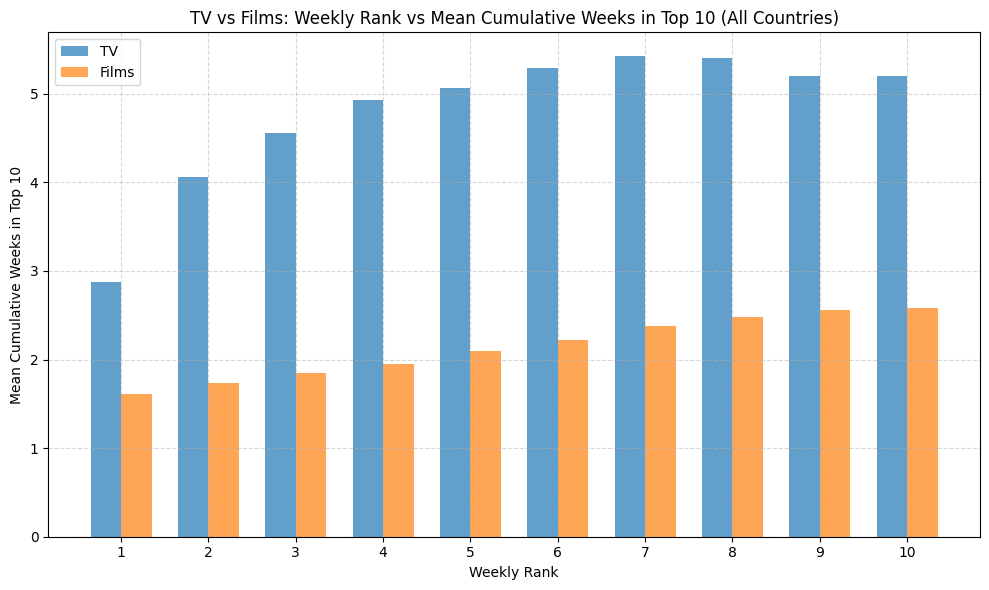

In [11]:
import matplotlib.pyplot as plt

# Filter for TV and Films only
subset_df = all_weeks_countries_netflix[all_weeks_countries_netflix['category'].isin(['TV', 'Films'])]

# Group by category and weekly_rank, then calculate mean cumulative_weeks_in_top_10
rank_means = (
    subset_df.groupby(['category', 'weekly_rank'])['cumulative_weeks_in_top_10']
    .mean()
    .reset_index()
)

# Pivot so categories become columns
rank_pivot = rank_means.pivot(index='weekly_rank', columns='category', values='cumulative_weeks_in_top_10')

# Plot
plt.figure(figsize=(10, 6))
width = 0.35
x = rank_pivot.index

plt.bar(x - width/2, rank_pivot['TV'], width=width, label='TV', alpha=0.7)
plt.bar(x + width/2, rank_pivot['Films'], width=width, label='Films', alpha=0.7)

plt.xlabel('Weekly Rank')
plt.ylabel('Mean Cumulative Weeks in Top 10')
plt.title('TV vs Films: Weekly Rank vs Mean Cumulative Weeks in Top 10 (All Countries)')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
